In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, '../../../src/')
import DoubleLayerWithHoles as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo

In [2]:
inside_solution = pd.read_csv('EigenvaluesEigenvectorsInsideSol_Dahne_MPI.csv', low_memory=False) 

In [3]:
inside_solution

,Eigenvalues,Eigenvectors0,Eigenvectors1,Inside0,Inside1,Solution0
0,[7.86103094+7.82774092e-07j 7.86103094+7.82975...,(0.00013350516350300003-0.0003160243331633994j),(-0.0006610698914991983+0.0005072781496915416j),-0.500125,-0.861471,(9.471097967654e-06-4.2053012714064406e-07j)
1,NaN,(0.0002644070746016175-4.676482588992837e-05j),(-0.0002342044626641015+0.0007111848324099624j),-0.494888,-0.861471,(1.8465165787976724e-05-2.8733808720171096e-06j)
2,NaN,(0.00017783471651309926+0.00012201431037296134j),(0.0003467065420703246+0.001023230138079754j),-0.489651,-0.861471,(2.2214500429536136e-05-7.2144127771845735e-06j)
3,NaN,(4.929324587092866e-05+0.00017125729223152494j),(0.0007386706491076383+0.0012408043982837583j),-0.484414,-0.861471,(2.5292549034976446e-05-1.0758558890729955e-05j)
4,NaN,(-0.00028242205804297337+0.0001735898162128518j),(0.0014935640597420244+0.0016419070056849935j),-0.479177,-0.861471,(2.8499133120243316e-05-1.3219602793261998e-05j)
...,...,...,...,...,...,...
88295,NaN,NaN,NaN,0.479177,0.861471,(-2.8500094827952445e-05+1.3220888940751506e-05j)
88296,NaN,NaN,NaN,0.484414,0.861471,(-2.5293520165158793e-05+1.0759842671258452e-05j)
88297,NaN,NaN,NaN,0.489651,0.861471,(-2.2215480645000488e-05+7.215694212967146e-06j)
88298,NaN,NaN,NaN,0.494888,0.861471,(-1.846615409669154e-05+2.874660414538743e-06j)


In [4]:
xy_inside = inside_solution[['Inside0', 'Inside1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [5]:
sol = inside_solution['Solution0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [6]:
faces = np.array([21,55,55,55,55])
n = 2*faces
alpha = (1-np.sqrt(3/5))/2

#Parameters for the hexagon
n_gon_hexagon = 6
side_length = 1
R = side_length/(2*np.sin(np.pi/n_gon_hexagon))
xm = 0
ym = 0
rot = 0
hexagon = DL.create_polygon(n_gon_hexagon,R,xm,ym,rot,n[0])

# Parameters for the triangle
n_gon_triangle = 3
height = 6/27
R = height*2/3
distance = 14/27
angles = np.linspace(0,2*np.pi, n_gon_hexagon, endpoint=False)

xm = distance*np.cos(angles)
ym = distance*np.sin(angles)

rot1 = 2*np.pi/3
rot2 = 2*np.pi/(3*2)
hexagon_triangles = np.empty(n_gon_hexagon+1, dtype=object)
hexagon_triangles[0] = hexagon

# Create 6 triangles at the correct positions
for i in range(n_gon_hexagon):
    if np.mod(i,2) == 0:
        triangle_temp = DL.create_polygon(n_gon_triangle,R,xm[i],ym[i],rot1,n[1])
    else:
        triangle_temp = DL.create_polygon(n_gon_triangle,R,xm[i],ym[i],rot2,n[1])
    tringle_flip = np.flip(triangle_temp,1)
    hexagon_triangles[i+1] = tringle_flip

# Stack all the boundaries together
vi = np.copy(hexagon_triangles)
collocation_nodes = np.empty(n_gon_hexagon+1, dtype= object)
for i in range(n_gon_hexagon+1):
    collocation_nodes[i] = DL.create_collocation_nodes(vi[i],alpha) 

In [7]:
hexagon_triangles_closed_curve = np.empty(n_gon_hexagon+1,dtype=object)
for i in range(n_gon_hexagon+1):
    hexagon_triangles_closed_curve[i] = np.hstack((hexagon_triangles[i],hexagon_triangles[i][:,0:1]))

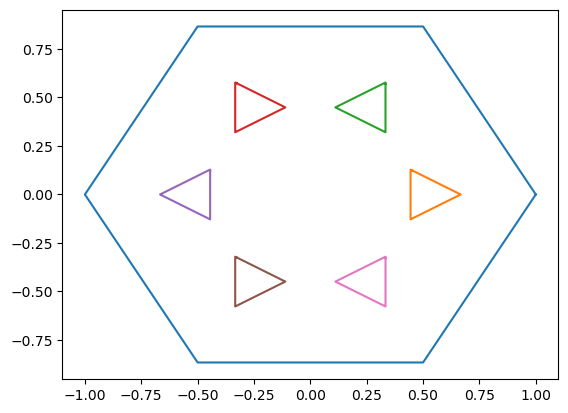

In [8]:
for i in range(n_gon_hexagon+1):
    plt.plot(hexagon_triangles_closed_curve[i][0,:], hexagon_triangles_closed_curve[i][1,:])

In [9]:
def ray_tracing_in_holes(boundary, xmid, ymid):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    x_start : float
        Start value of a square in x-direction.
    x_end : float
        End value of a square in x-direction.
    x_steps : int
        Number of points in x-direction that should be checked to be inside the given domain without holes.
    y_start : float
        Start value of a square in y-direction.
    y_end : float
        End value of a square in y-direction.
    y_steps : int
        Number of points in y-direction that should be checked to be inside the given domain without holes.

    Returns
    -------
    xy_inside : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [10]:
eigenvalues = inside_solution['Eigenvalues'][0]
eigenvalues

'[7.86103094+7.82774092e-07j 7.86103094+7.82975060e-07j]'

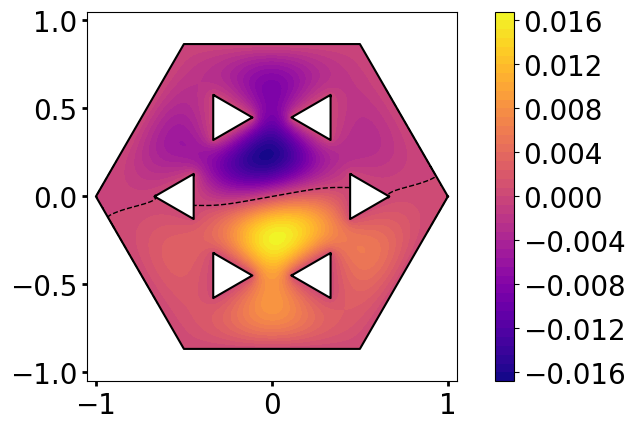

In [11]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)

vmin_sol=np.sort(real_sol)[0]
vmax_sol=np.sort(real_sol)[-1]
# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)
mask1 = ray_tracing_in_holes(np.array([hexagon_triangles_closed_curve[0]]), xmid, ymid)
mask2 = ray_tracing_in_holes(np.array([hexagon_triangles_closed_curve[1]]), xmid, ymid)
mask3 = ray_tracing_in_holes(np.array([hexagon_triangles_closed_curve[2]]), xmid, ymid)
mask4 = ray_tracing_in_holes(np.array([hexagon_triangles_closed_curve[3]]), xmid, ymid)
mask5 = ray_tracing_in_holes(np.array([hexagon_triangles_closed_curve[4]]), xmid, ymid)
mask6 = ray_tracing_in_holes(np.array([hexagon_triangles_closed_curve[5]]), xmid, ymid)
mask7 = ray_tracing_in_holes(np.array([hexagon_triangles_closed_curve[6]]), xmid, ymid)

mask1_inv = ~mask1
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7
triang.set_mask(mask)

# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
cf = plt.tricontourf(triang, real_sol, cmap='plasma',levels= 40)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1)

cbar = plt.colorbar(cf, label='')#Funktionswert f(x, y)')
cbar.ax.tick_params(labelsize=20)

plt.axis('square')

plt.xlim(-1.05,1.05)
plt.ylim(-1.05,1.05)
for i in range(n_gon_hexagon+1):
    plt.plot(hexagon_triangles_closed_curve[i][0,:], hexagon_triangles_closed_curve[i][1,:], color='black')
plt.savefig('hexagon_six_triangles_14_24.eps', format="eps")
plt.show()